In [1]:
import os
os.chdir('/home/hedi/HSCNG/')
import multiprocessing as mp

import numpy as np
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.wcs import WCS
from astropy import units as u
import pymaster as nmt
import tqdm

from hsc_y3_utils import map_utils, stats_code
import matplotlib.pyplot as plt

name_fields = ['XMM', 'VVDS', 'GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
number_patches = [8, 25, 23, 7, 26, 13]
tomo_bin = [1, 2, 3, 4]
pixscale_arcmin = 0.5   # 0.5 arcmin → degrees/pixel
pixscale_deg = pixscale_arcmin / 60.0
smoothing_kernel_size = 1   # arcmin

tomo_bin = [1, 2, 3, 4]         # tomo_bin, 0 is excluded.
_GALAXY_COUNTS_TOMOBIN_ = {}

for field, Npatch in zip(name_fields, number_patches):
    dats = [
        fits.getdata(f'data/real/hscy3_shape_chopped_{field}_{i}.fits')
        for i in range(Npatch)
    ]
    dat = np.concatenate(dats)
    _numbers = []
    for tomo_bin in [1, 2, 3, 4]:
        _numbers.append((dat['hsc_y3_zbin'] == tomo_bin).sum())
    _GALAXY_COUNTS_TOMOBIN_[field] = _numbers


cmap = plt.cm.viridis.copy()
cmap.set_bad('white')
binning = np.linspace(-6, 6, 50)

# load map information

notes about the map info:

- the g1 g2 is the original map, which is unsmoothed
- kappa kappa i might be smoothed (depending on procedure str), but unmasked.
- weight_mask, nmap is original map, which is unsmoothed

Problem here: the errors seems too small compared with the signal?

In [2]:
def load_map_info(file):
    with fits.open(file) as map_fits:
        map_info = {}
        names = [
            'G1', 'G2', 'KAPPA', 'KAPPA_I', 'WEIGHT_MASK', 'NMAP'
        ]
        keys = [
            'g1', 'g2', 'kappa', 'kappa_i', 'weight_mask', 'nmap'
        ]
        for name, key in zip(names, keys):
            map_info[key] = map_fits[name].data
        map_info['wcs'] = WCS(map_fits[0].header)
    return map_info

def load_map_info_real(field, tomo_bin, procedure):
    file_name = f"maps/real/kappa_map_{field}_z{tomo_bin}_{procedure}.fits"
    return load_map_info(file_name)

def load_map_info_mock(field, tomo_bin, procedure, cosmo_number):
    maps = []
    for i in range(25):
        maps.append(load_map_info(f"maps/mock/node{cosmo_number:02d}_a/cone{i+1}/kappa_map_mock_{field}_z{tomo_bin}_{procedure}.fits"))
        maps.append(load_map_info(f"maps/mock/node{cosmo_number:02d}_b/cone{i+1}/kappa_map_mock_{field}_z{tomo_bin}_{procedure}.fits"))
    # each cosmo par has 2 phases, each phase has 25 cones, total 50 maps for each field and tomo_bin.
    return maps

In [ ]:
cosmo_number = 0
phase = 'a'
field = 'XMM'
tomo = 1
procedure = 'smooth g-inpainting-KSI-masking'
cone_number = 1

In [5]:
%%timeit
map_info = load_map_info(f"maps/mock/node{cosmo_number:02d}_{phase}/cone{cone_number}/kappa_map_mock_{field}_z{tomo}_{procedure}.fits")
bad = np.isnan(map_info['kappa']).any()

10.4 ms ± 233 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [ ]:
import pandas as pd
dat = pd.DataFrame(columns=['cosmo', 'phase', 'cone', 'field', 'tomo', 'procedure'])

procedure = 'smooth g-inpainting-KSI-masking'  # Example procedure, adjust as needed
for cosmo_number in range(50):
    for phase in ['a', 'b']:
        for cone_number in range(1, 26):
            for field in name_fields:
                for tomo in tomo_bin:
                    map_info = load_map_info(f"maps/mock/node{cosmo_number:02d}_{phase}/cone{cone_number}/kappa_map_mock_{field}_z{tomo_bin}_{procedure}.fits")
                    if np.isnan(map_info['kappa']).any():
                        print(f"NaN found in kappa map for field {field}, tomo {tomo}, procedure {procedure}, cosmo {cosmo_number}, map index {i}")
                        dat.loc[len(dat)] = [cosmo_number, phase, cone_number, field, tomo, procedure]

# save bad map info
out_csv = 'bad_maps.csv'
dat.to_csv(out_csv, index=False)
print(f"Saved {len(dat)} bad map entries to {out_csv}")

In [3]:
def compute_pdf_mock(procedure, field, tomo_bin, binning, cosmo, mask='original'):
    map_info_mock = load_map_info_mock(field, tomo_bin, procedure, cosmo)
    map_info = map_info_mock[0]     # the first mock map is used to get the mask and wcs info, which are the same for all mocks.
    flatobj = map_utils.FlatClass(map_info['wcs'], map_info['kappa'].shape[1], map_info['kappa'].shape[0])

    kappa_smoothed_list = []
    for i in range(len(map_info_mock)):
        kappa_smoothed_list.append(
            flatobj.smooth_G(map_info_mock[i]['kappa'], smoothing_kernel_size / pixscale_arcmin)
        )

    kappa_mock_list = np.array(kappa_smoothed_list)
    kappa_mock_list -= kappa_mock_list.mean(axis=(1, 2))[:,None,None]

    sigma = kappa_mock_list.std()
    kappa_sigma_ratio_mock = kappa_mock_list / sigma

    original_mask = map_info['weight_mask'] > 0

    Npatch = number_patches[name_fields.index(field)]
    dats = [
        fits.getdata(f'data/real/hscy3_shape_chopped_{field}_{i}.fits')
        for i in range(Npatch)
    ]
    dat = np.concatenate(dats)
    dat = dat[dat['hsc_y3_zbin'] == tomo_bin]
    smoothed_weight = flatobj.smooth_G(map_info['weight_mask'], smoothing_kernel_size / pixscale_arcmin)

    mask_criterion_loose = (smoothed_weight > dat['i_hsmshaperegauss_derived_weight'].min() * 0.8) & original_mask
    ys = []
    for k in kappa_sigma_ratio_mock:
        x, hist = stats_code.pdf(data=k, thresholds=binning, mask=mask_criterion_loose)
        if np.isnan(hist).any():
            print(f"Warning: NaN values found in histogram for field {field}, tomo_bin {tomo_bin}, cosmo {cosmo}. This may affect the results.")
        ys.append(hist)

    return (x, np.mean(ys, axis=0), np.cov(ys, rowvar=False))

In [4]:
# field = 'GAMA09H'
tomo = 1
procedure = 'smooth g-inpainting-KSI-masking'
cosmo = 12

for f in name_fields:
    x, y, cov = compute_pdf_mock(procedure, f, tomo, binning, cosmo)
    if np.isnan(y).any():
        print(f"Warning: NaN values found in mean histogram for field {f}, tomo_bin {tomo}, cosmo {cosmo}. This may affect the results.")

In [6]:
field = 'VVDS'
tomo = 1
procedure = 'smooth g-inpainting-KSI-masking'
cosmo = 12

map_info = load_map_info_real(field, tomo, procedure)
map_info_mock = load_map_info_mock(field, tomo, procedure, cosmo)

In [12]:
flatobj = map_utils.FlatClass(map_info['wcs'], map_info['kappa'].shape[1], map_info['kappa'].shape[0])

kappa_smoothed_list = []
for i in range(len(map_info_mock)):
    kappa_smoothed_list.append(
        flatobj.smooth_G(map_info_mock[i]['kappa'], smoothing_kernel_size / pixscale_arcmin)
    )
kappa_mock_list = np.array(kappa_smoothed_list)

kappa_real = flatobj.smooth_G(map_info['kappa'], smoothing_kernel_size / pixscale_arcmin)

original_mask = map_info['weight_mask'] > 0

Npatch = number_patches[name_fields.index(field)]
dats = [
    fits.getdata(f'data/real/hscy3_shape_chopped_{field}_{i}.fits')
    for i in range(Npatch)
]
dat = np.concatenate(dats)
dat = dat[dat['hsc_y3_zbin'] == tomo_bin]
smoothed_weight = flatobj.smooth_G(map_info['weight_mask'], smoothing_kernel_size / pixscale_arcmin)

mask_criterion_loose = (smoothed_weight > dat['i_hsmshaperegauss_derived_weight'].min() * 0.8) & original_mask


kappa_mock_list -= kappa_mock_list.mean(axis=(1, 2))[:,None,None]

sigma = kappa_mock_list[:,mask_criterion_loose].std()
kappa_sigma_ratio_mock = kappa_mock_list / sigma
kappa_sigma_ratio = kappa_real / sigma

mask = mask_criterion_loose

# Smooth the kappa map

# apply mask to the kappa map

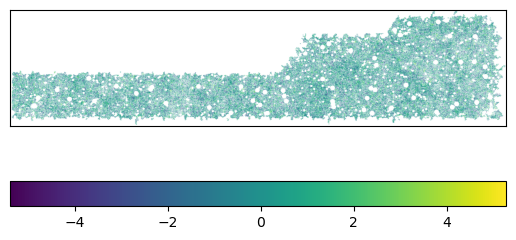

In [11]:
kappa_plot = np.ma.masked_array(kappa_sigma_ratio, mask=~mask_criterion_loose)

plt.imshow(kappa_plot, origin='lower', cmap=cmap)
plt.xticks([])
plt.yticks([])
plt.colorbar(orientation='horizontal')

# apply NG stats

## PDF

Text(0.5, 1.0, 'PDF')

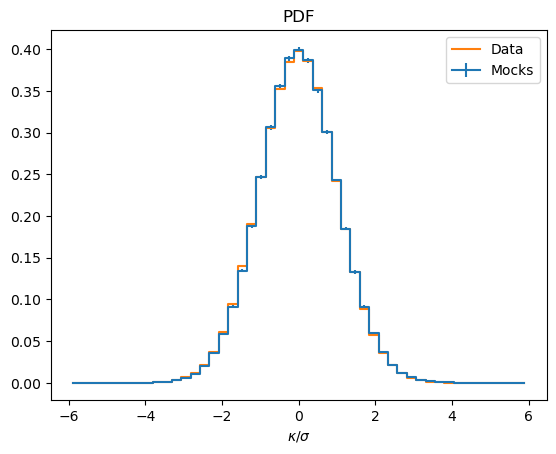

In [ ]:
x, y_real = stats_code.pdf(kappa_sigma_ratio, binning, norm=False, mask=mask)

ys = []
for kappa_mock in kappa_mock_list:
    x, y = stats_code.pdf(kappa_mock / sigma, binning, norm=False, mask=mask)
    ys.append(y)

yerr = np.std(ys, axis=0)

plt.errorbar(x, np.mean(ys, axis=0), yerr=yerr, drawstyle='steps-mid', label='Mocks')
plt.plot(x, y_real, drawstyle='steps-mid', label='Data')

plt.legend()
plt.xlabel(r'$\kappa / \sigma$')
plt.title('PDF')

### Different fields and tomo bins

In [182]:
def pdf_field_tomo(field, tomo_bin, procedure, cosmo, binning, mask='original'):
    map_info = load_map_info_real(field, tomo_bin, procedure)
    map_info_mock = load_map_info_mock(field, tomo_bin, procedure, cosmo)

    kappa = map_info['kappa']
    flatobj = map_utils.FlatClass(map_info['wcs'], kappa.shape[1], kappa.shape[0])
    kappa_real = flatobj.smooth_G(kappa, smoothing_kernel_size / pixscale_arcmin)

    kappa_smoothed_list = []
    for i in range(25):
        kappa_smoothed_list.append(
            flatobj.smooth_G(map_info_mock[i]['kappa'], smoothing_kernel_size / pixscale_arcmin)
        )
    kappa_mock_list = np.array(kappa_smoothed_list)

    # use original mask directly
    original_mask = map_info['weight_mask'] > 0
    if mask == 'original':
        mask = ~original_mask           # simple mask, can be replaced by more complex masks later.
    elif isinstance(mask, float) and 0 < mask < 1:
        threshold = mask
        smoothed_weight = flatobj.smooth_G(map_info['weight_mask'], smoothing_kernel_size / pixscale_arcmin)
        weight_ratio = np.divide(smoothed_weight, map_info['weight_mask'],\
            out=np.zeros_like(smoothed_weight, dtype=float), where=map_info['weight_mask']!=0)
        # avoid division by zero here.
        mask_ratio = weight_ratio > threshold
        mask = ~mask_ratio
    else:
        raise ValueError("Invalid mask type. Use 'original' or a float value for thresholding.")

    
    sigma = kappa_mock_list.std(axis=0)
    kappa_sigma_ratio = kappa_real / sigma

    x, y_real = stats_code.pdf(kappa_sigma_ratio, binning, norm=False, mask=mask)
    ys = []
    for kappa_mock in kappa_mock_list:
        x, y = stats_code.pdf(kappa_mock / sigma, binning, norm=False, mask=mask)
        ys.append(y)

    yerr = np.std(ys, axis=0)
    y_cov = np.cov(ys, rowvar=False)
    y_mean = np.mean(ys, axis=0)

    return x, y_real, y_mean, yerr, y_cov

Text(0.5, 1.0, 'PDF HECTOMAP- z2')

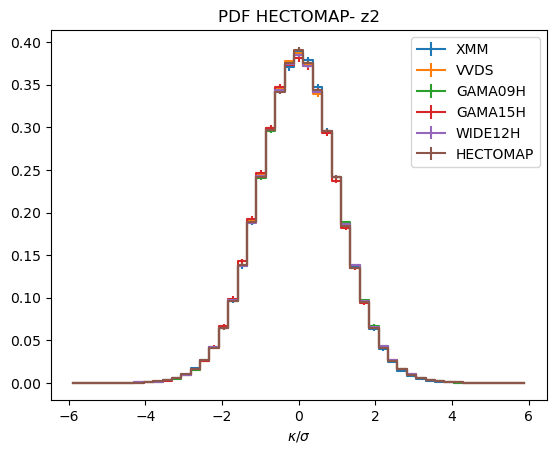

In [183]:
field = 'GAMA09H'
tomo_bin = 2
procedure = 'smooth g-inpainting-KSI-masking'

for field in name_fields:
    x, y, y_mean, yerr, _ = pdf_field_tomo(field, tomo_bin, procedure=procedure, cosmo=0, binning=binning, mask='original')
    plt.errorbar(x, y, yerr=yerr, drawstyle='steps-mid', label=field)

# plt.plot(x, y, drawstyle='steps-mid', label='Data')
# plt.errorbar(x, y_mean, yerr=yerr, drawstyle='steps-mid', label='Mocks')
plt.legend()
plt.xlabel(r'$\kappa / \sigma$')
plt.title('PDF {}- z{}'.format(field, tomo_bin))

In [184]:
def compute_pdf_average(pipeline, tomo_bin, binning, cosmo, mask='original', weight='inverse_cov'):
    x = None
    signal_list = []
    cov_list = []
    for field in name_fields:
        x, y, y_mean, yerr, y_cov = pdf_field_tomo(field, tomo_bin, procedure=pipeline, cosmo=cosmo, binning=binning, mask=mask)
        signal_list.append(y)
        cov_list.append(y_cov)
    signal_array = np.array(signal_list)
    cov_array = np.array(cov_list)
    nbin = len(x)
    if weight == 'galaxy_number':
        number_galaxies = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo_bin - 1] for field in name_fields
        ]
        w = np.asarray(number_galaxies, dtype=float)
        wsum = w.sum()
        s_mean = np.average(signal_array, axis=0, weights=w)
        C_mean = np.tensordot(w**2, cov_array, axes=(0, 0)) / (wsum**2)
        # chi2_val = s_mean @ np.linalg.solve(C_mean, s_mean)
        return x, s_mean, C_mean
    elif weight == 'inverse_cov':
    # 3) Inverse-cov weighted (recommended): s_icov, C_icov
        P = np.zeros((nbin, nbin))
        b = np.zeros(nbin)
        for s, C in zip(signal_array, cov_array):
            # use solve for better stability than explicit inverse
            P += np.linalg.solve(C, np.eye(nbin))
            b += np.linalg.solve(C, s)

        C_icov = np.linalg.inv(P)
        s_icov = C_icov @ b
        # S/N for combined signal (pick which combo you want)
        # chi2_val = s_icov @ np.linalg.solve(C_icov, s_icov)

        return x, s_icov, C_icov
    else:
        raise ValueError("Invalid weight option")

In [186]:
x, s, cov = compute_pdf_average(procedure, tomo_bin, binning, cosmo=1, mask='original', weight='galaxy_number')

/home/hedi/data/miniforge3/lib/python3.12/site-packages/numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges


Text(0.5, 1.0, 'Combined PDF - smooth g-inpainting-KSI-masking - z2')

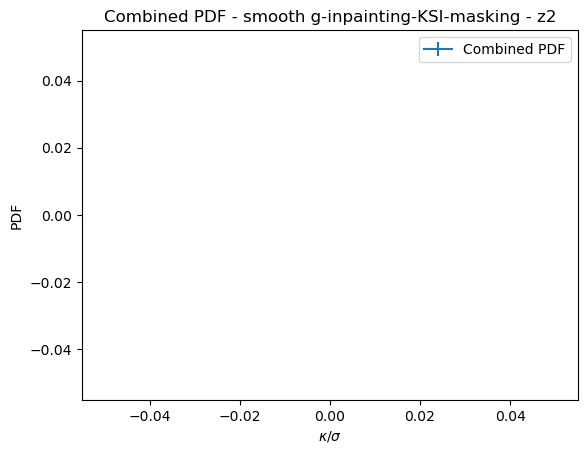

In [187]:
plt.errorbar(x, s, yerr=np.sqrt(np.diag(cov)), drawstyle='steps-mid', label='Combined PDF')
plt.legend()
plt.xlabel(r'$\kappa / \sigma$')
plt.ylabel('PDF')
plt.title('Combined PDF - {} - z{}'.format(procedure, tomo_bin))

## Peaks & Minimun

In [13]:
def peaks_minimums(masked_kappa, mask, bins):
    count_p, edge = stats_code.peaks_histogram(masked_kappa, mask=mask, bins=bins)
    count_m, edge = stats_code.peaks_histogram(-masked_kappa, mask=mask, bins=bins)
    return edge, count_p, count_m

In [17]:
binning = np.linspace(-4, 4, 20)

In [18]:
x, y_p, y_m = peaks_minimums(kappa_sigma_ratio, mask, bins=binning)

In [19]:
yps = []
yms = []

for i in range(25):
    x, y_p, y_m = peaks_minimums(kappa_sigma_ratio_mock[i], mask, bins=binning)
    yps.append(y_p)
    yms.append(y_m)

yp_m = np.mean(yps, axis=0)
ym_m = np.mean(yms, axis=0)
yp_std = np.std(yps, axis=0)
ym_std = np.std(yms, axis=0)

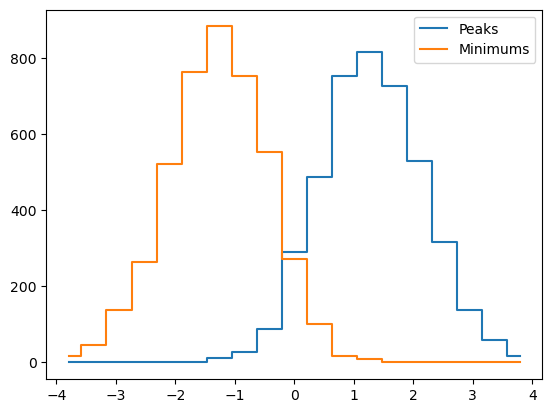

In [20]:
plt.plot(x, y_p, drawstyle='steps-mid', label='Peaks')
plt.plot(-x, y_m, drawstyle='steps-mid', label='Minimums')
plt.legend()

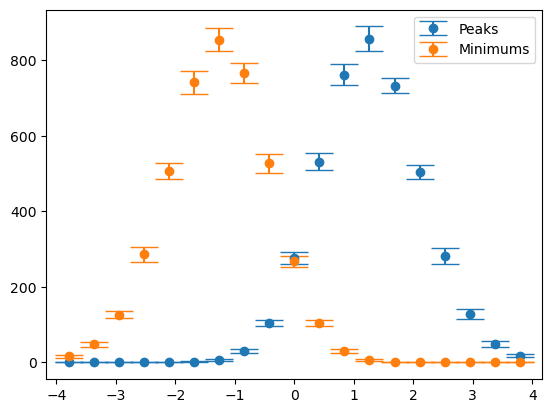

In [21]:
plt.errorbar(x, yp_m, yerr=yp_std, fmt='o', capsize=10, label='Peaks')
plt.errorbar(-x, ym_m, yerr=ym_std, fmt='o', capsize=10, label='Minimums')
plt.legend()

In [29]:
def compute_p_m(mask):
    kappa_masked = np.ma.MaskedArray(kappa_smoothed, mask=mask)
    kappa_masked_list = []
    for i in range(25):
        kappa_mock_masked = np.ma.MaskedArray(kappa_smoothed_list[i], mask=mask)
        kappa_masked_list.append(kappa_mock_masked)
    kappa_masked_list = np.ma.MaskedArray(kappa_masked_list)
    sigma = kappa_masked_list.std(axis=0)
    kappa_sigma_ratio = kappa_masked / sigma

    assert (kappa_sigma_ratio.mask == mask).all()     # the mask is passed correctly.
    
    kappa_sigma_ratio_mock = [kappa_mock / sigma for kappa_mock in kappa_masked_list]

    x, p_real, m_real = peaks_minimums(kappa_sigma_ratio, bins=binning)
    
    ps = []
    ms = []
    for kappa_mock in kappa_sigma_ratio_mock:
        x, p, m = peaks_minimums(kappa_mock, bins=binning)
        ps.append(p)
        ms.append(m)

    perr = np.std(ps, axis=0)
    merr = np.std(ms, axis=0)

    return x, p_real, m_real, perr, merr

In [31]:
def peaks_minimums_field_tomo(field, tomo_bin, procedure, cosmo, binning, mask='original'):
    # TODO: Do we somehow normalize the counts so that they can be combined together? maybe add them up instead?

    map_info = load_map_info_real(field, tomo_bin, procedure)
    map_info_mock = load_map_info_mock(field, tomo_bin, procedure, cosmo)

    kappa = map_info['kappa']
    flatobj = map_utils.FlatClass(map_info['wcs'], kappa.shape[1], kappa.shape[0])
    kappa_smoothed = flatobj.smooth_G(kappa, smoothing_kernel_size / pixscale_arcmin)

    kappa_smoothed_list = []
    for i in range(25):
        kappa_smoothed_list.append(
            flatobj.smooth_G(map_info_mock[i]['kappa'], smoothing_kernel_size / pixscale_arcmin)
        )

    # use original mask directly
    original_mask = map_info['weight_mask'] > 0
    if mask == 'original':
        mask = ~original_mask           # simple mask, can be replaced by more complex masks later.
    elif isinstance(mask, float) and 0 < mask < 1:
        threshold = mask
        smoothed_weight = flatobj.smooth_G(map_info['weight_mask'], smoothing_kernel_size / pixscale_arcmin)
        weight_ratio = np.divide(smoothed_weight, map_info['weight_mask'],\
            out=np.zeros_like(smoothed_weight, dtype=float), where=map_info['weight_mask']!=0)
        # avoid division by zero here.
        mask_ratio = weight_ratio > threshold
        mask = ~mask_ratio
    else:
        raise ValueError("Invalid mask type. Use 'original' or a float value for thresholding.")

    Npix = mask.astype(float).sum()

    kappa_masked = np.ma.MaskedArray(kappa_smoothed, mask=mask)
    kappa_masked_list = []
    for i in range(25):
        kappa_mock_masked = np.ma.MaskedArray(kappa_smoothed_list[i], mask=mask)
        kappa_masked_list.append(kappa_mock_masked)
    kappa_masked_list = np.ma.MaskedArray(kappa_masked_list)
    sigma = kappa_masked_list.std(axis=0)
    kappa_sigma_ratio = kappa_masked / sigma

    assert (kappa_sigma_ratio.mask == mask).all()     # the mask is passed correctly.
    
    kappa_sigma_ratio_mock = [kappa_mock / sigma for kappa_mock in kappa_masked_list]
    x, p_real, m_real = peaks_minimums(kappa_sigma_ratio, binning)
    # p_real = p_real / Npix
    # m_real = m_real / Npix

    ps = []
    ms = []
    for kappa_mock in kappa_sigma_ratio_mock:
        x, p, m = peaks_minimums(kappa_mock, binning)
        # p = p / Npix
        # m = m / Npix
        ps.append(p)
        ms.append(m)

    perr = np.std(ps, axis=0)
    merr = np.std(ms, axis=0)
    p_cov = np.cov(ps, rowvar=False)
    m_cov = np.cov(ms, rowvar=False)
    p_mean = np.mean(ps, axis=0)
    m_mean = np.mean(ms, axis=0)

    return (x, p_real, p_mean, perr, p_cov), (x, m_real, m_mean, merr, m_cov)

Text(0.5, 1.0, 'Peaks HECTOMAP- z2')

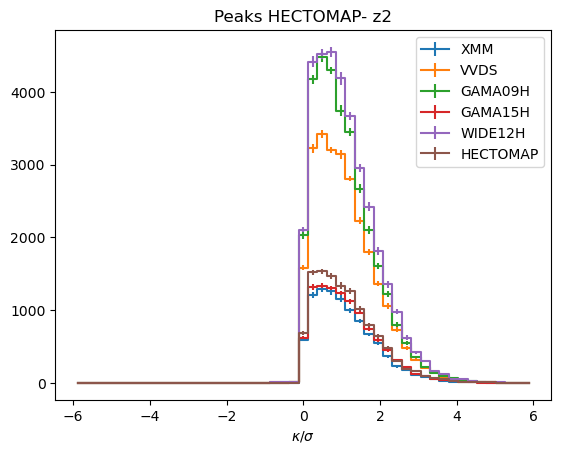

In [ ]:
field = 'GAMA09H'
tomo_bin = 2
procedure = 'smooth g-inpainting-KSI-masking'

for field in name_fields:
    (x, p, p_mean, perr, _), (x, m, m_mean, merr, _) = peaks_minimums_field_tomo(field, tomo_bin, procedure=procedure, cosmo=0, binning=binning, mask='original')
    plt.errorbar(x, p, yerr=perr, drawstyle='steps-mid', label=field)

# plt.plot(x, y, drawstyle='steps-mid', label='Data')
# plt.errorbar(x, y_mean, yerr=yerr, drawstyle='steps-mid', label='Mocks')
plt.legend()
plt.xlabel(r'$\kappa / \sigma$')
plt.title('=z{}'.format(tomo_bin))

## MF

In [22]:
x, V0, V1,V2 = stats_code.MFs(kappa_sigma_ratio, nu=np.linspace(-6, 6, 30))

# TODO: why MFs doesn't take into account the mask?

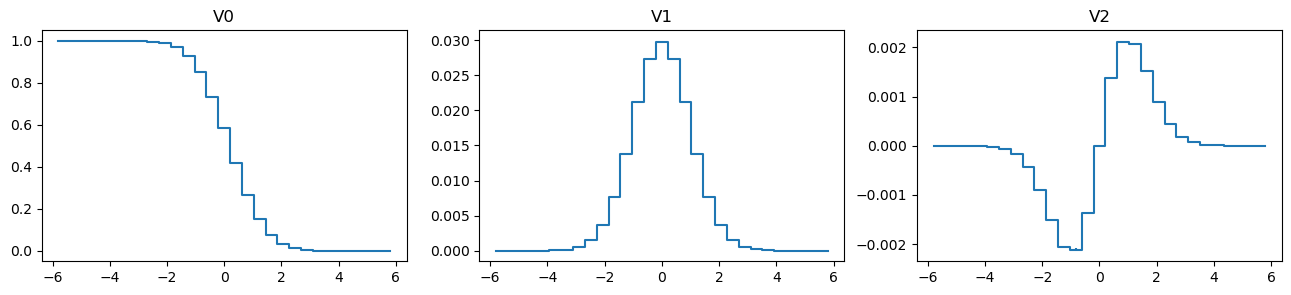

In [25]:
V0s = []
V1s = []
V2s = []
for k in kappa_sigma_ratio_mock:
    x, V0_m, V1_m,V2_m = stats_code.MFs(k, nu=np.linspace(-6, 6, 30))
    V0s.append(V0_m)
    V1s.append(V1_m)
    V2s.append(V2_m)

V0m = np.mean(V0s, axis=0)
V1m = np.mean(V1s, axis=0)
V2m = np.mean(V2s, axis=0)

fig, axes = plt.subplots(1, 3, figsize=(16, 3))

axes[0].errorbar(x, V0m, np.std(V0s, axis=0), drawstyle='steps-mid', label='V0')
axes[1].errorbar(x, V1m, np.std(V1s, axis=0), drawstyle='steps-mid', label='V1')
axes[2].errorbar(x, V2m, np.std(V2s, axis=0), drawstyle='steps-mid', label='V2')

axes[0].set_title('V0')
axes[1].set_title('V1')
axes[2].set_title('V2')

plt.show()

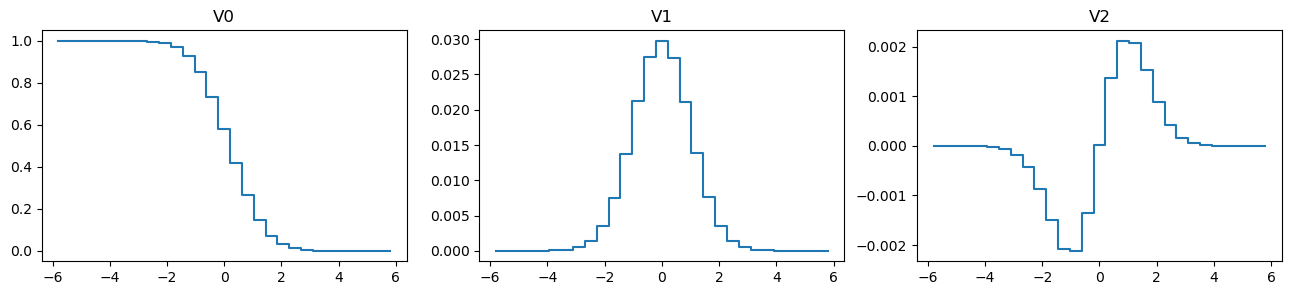

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3))

axes[0].plot(x, V0, drawstyle='steps-mid', label='V0')
axes[1].plot(x, V1, drawstyle='steps-mid', label='V1')
axes[2].plot(x, V2, drawstyle='steps-mid', label='V2')

axes[0].set_title('V0')
axes[1].set_title('V1')
axes[2].set_title('V2')

plt.show()

In [35]:
def compute_MF(mask):
    kappa_masked = np.ma.MaskedArray(kappa_smoothed, mask=mask)
    kappa_masked_list = []
    for i in range(25):
        kappa_mock_masked = np.ma.MaskedArray(kappa_smoothed_list[i], mask=mask)
        kappa_masked_list.append(kappa_mock_masked)
    kappa_masked_list = np.ma.MaskedArray(kappa_masked_list)
    sigma = kappa_masked_list.std(axis=0)
    kappa_sigma_ratio = kappa_masked / sigma

    assert (kappa_sigma_ratio.mask == mask).all()     # the mask is passed correctly.
    
    kappa_sigma_ratio_mock = [kappa_mock / sigma for kappa_mock in kappa_masked_list]

    x, V0_real, V1_real, V2_real = stats_code.MFs(kappa_sigma_ratio.filled(0), nu=binning)
    
    V0s = []
    V1s = []
    V2s = []
    for kappa_mock in kappa_sigma_ratio_mock:
        x, V0, V1, V2 = stats_code.MFs(kappa_mock.filled(0), nu=binning)
        V0s.append(V0)
        V1s.append(V1)
        V2s.append(V2)

    V0err = np.std(V0s, axis=0)
    V1err = np.std(V1s, axis=0)
    V2err = np.std(V2s, axis=0)

    return x, V0_real, V1_real, V2_real, V0err, V1err, V2err

In [59]:
def MFs_field_tomo(field, tomo_bin, procedure, cosmo, binning, mask='original'):
    # TODO: Do we somehow normalize the counts so that they can be combined together? maybe add them up instead?

    map_info = load_map_info_real(field, tomo_bin, procedure)
    map_info_mock = load_map_info_mock(field, tomo_bin, procedure, cosmo)

    kappa = map_info['kappa']
    flatobj = map_utils.FlatClass(map_info['wcs'], kappa.shape[1], kappa.shape[0])
    kappa_smoothed = flatobj.smooth_G(kappa, smoothing_kernel_size / pixscale_arcmin)

    kappa_smoothed_list = []
    for i in range(25):
        kappa_smoothed_list.append(
            flatobj.smooth_G(map_info_mock[i]['kappa'], smoothing_kernel_size / pixscale_arcmin)
        )

    # use original mask directly
    original_mask = map_info['weight_mask'] > 0
    if mask == 'original':
        mask = ~original_mask           # simple mask, can be replaced by more complex masks later.
    elif isinstance(mask, float) and 0 < mask < 1:
        threshold = mask
        smoothed_weight = flatobj.smooth_G(map_info['weight_mask'], smoothing_kernel_size / pixscale_arcmin)
        weight_ratio = np.divide(smoothed_weight, map_info['weight_mask'],\
            out=np.zeros_like(smoothed_weight, dtype=float), where=map_info['weight_mask']!=0)
        # avoid division by zero here.
        mask_ratio = weight_ratio > threshold
        mask = ~mask_ratio
    else:
        raise ValueError("Invalid mask type. Use 'original' or a float value for thresholding.")

    Npix = mask.astype(float).sum()

    kappa_masked = np.ma.MaskedArray(kappa_smoothed, mask=mask)
    kappa_masked_list = []
    for i in range(25):
        kappa_mock_masked = np.ma.MaskedArray(kappa_smoothed_list[i], mask=mask)
        kappa_masked_list.append(kappa_mock_masked)
    kappa_masked_list = np.ma.MaskedArray(kappa_masked_list)
    sigma = kappa_masked_list.std(axis=0)
    kappa_sigma_ratio = kappa_masked / sigma

    assert (kappa_sigma_ratio.mask == mask).all()     # the mask is passed correctly.
    
    kappa_sigma_ratio_mock = [kappa_mock / sigma for kappa_mock in kappa_masked_list]
    x, V0_real, V1_real, V2_real = stats_code.MFs(kappa_sigma_ratio.filled(0), binning)

    V0s = []
    V1s = []
    V2s = []
    for kappa_mock in kappa_sigma_ratio_mock:
        x, V0, V1, V2 = stats_code.MFs(kappa_mock.filled(0), binning)
        V0s.append(V0)
        V1s.append(V1)
        V2s.append(V2)
    
    ret = []
    for V_real, V_list in zip([V0_real, V1_real, V2_real], [V0s, V1s, V2s]):
        V_err = np.std(V_list, axis=0)
        V_mean = np.mean(V_list, axis=0)
        V_cov = np.cov(V_list, rowvar=False)
        ret.append((x, V_real, V_mean, V_err, V_cov))

    return tuple(ret)

/misc/home/hedi/HSCNG/hsc_y3_utils/stats_code.py:85: RuntimeWarning: invalid value encountered in divide
  frac = (2*kx*ky*kxy - kx**2*kyy -ky**2*kxx)/(kx**2+ky**2)
/misc/home/hedi/HSCNG/hsc_y3_utils/stats_code.py:85: RuntimeWarning: invalid value encountered in divide
  frac = (2*kx*ky*kxy - kx**2*kyy -ky**2*kxx)/(kx**2+ky**2)
/misc/home/hedi/HSCNG/hsc_y3_utils/stats_code.py:85: RuntimeWarning: invalid value encountered in divide
  frac = (2*kx*ky*kxy - kx**2*kyy -ky**2*kxx)/(kx**2+ky**2)
/misc/home/hedi/HSCNG/hsc_y3_utils/stats_code.py:85: RuntimeWarning: invalid value encountered in divide
  frac = (2*kx*ky*kxy - kx**2*kyy -ky**2*kxx)/(kx**2+ky**2)
/misc/home/hedi/HSCNG/hsc_y3_utils/stats_code.py:85: RuntimeWarning: invalid value encountered in divide
  frac = (2*kx*ky*kxy - kx**2*kyy -ky**2*kxx)/(kx**2+ky**2)
/misc/home/hedi/HSCNG/hsc_y3_utils/stats_code.py:85: RuntimeWarning: invalid value encountered in divide
  frac = (2*kx*ky*kxy - kx**2*kyy -ky**2*kxx)/(kx**2+ky**2)


Text(0.5, 1.0, 'V2')

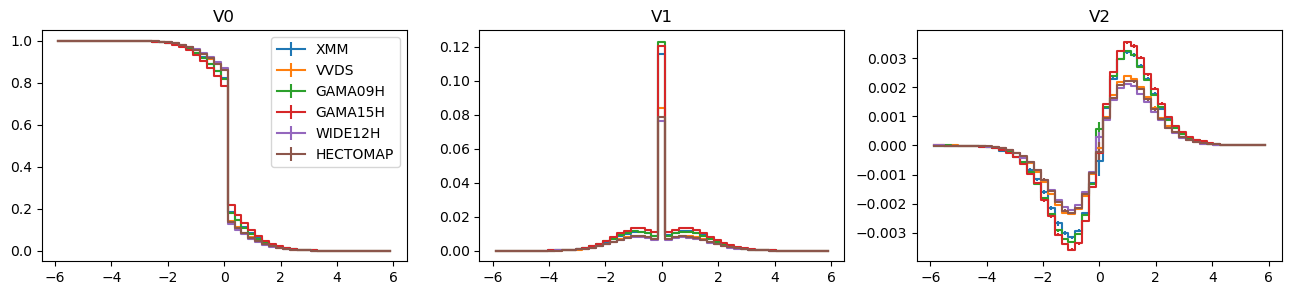

In [63]:
field = 'GAMA09H'
tomo_bin = 2
procedure = 'smooth g-inpainting-KSI-masking'

fig, axes = plt.subplots(1, 3, figsize=(16, 3))

for field in name_fields:
    ret = MFs_field_tomo(field, tomo_bin, procedure=procedure, cosmo=0, binning=binning, mask='original')
    for i in range(3):
        x, y, y_mean, yerr, _ = ret[i]
        axes[i].errorbar(x, y, yerr=yerr, drawstyle='steps-mid', label=field)

# plt.plot(x, y, drawstyle='steps-mid', label='Data')
# plt.errorbar(x, y_mean, yerr=yerr, drawstyle='steps-mid', label='Mocks')
axes[0].legend()

axes[0].set_title('V0')
axes[1].set_title('V1')
axes[2].set_title('V2')

# test on maskings

In [36]:
# 1. use original mask directly
original_mask = map_info['weight_mask'] > 0

kappa_masked = np.ma.MaskedArray(map_info['kappa'], mask=~original_mask)
kappa_masked_list = []
for i in range(25):
    assert np.array_equal(map_info_mock[i]['weight_mask'] > 0, original_mask), f"Mask of mock {i} does not match the original mask."
    kappa_mock_masked = np.ma.MaskedArray(map_info_mock[i]['kappa'], mask=~original_mask)
    kappa_masked_list.append(kappa_mock_masked)
kappa_masked_list = np.array(kappa_masked_list)

In [37]:
# 2. use the smoothed mask
flatobj = map_utils.FlatClass(map_info['wcs'], map_info['kappa'].shape[1], map_info['kappa'].shape[0])      # shape == (ny, nx)
smoothed_weight = flatobj.smooth_G(map_info['weight_mask'], smoothing_kernel_size / pixscale_arcmin)

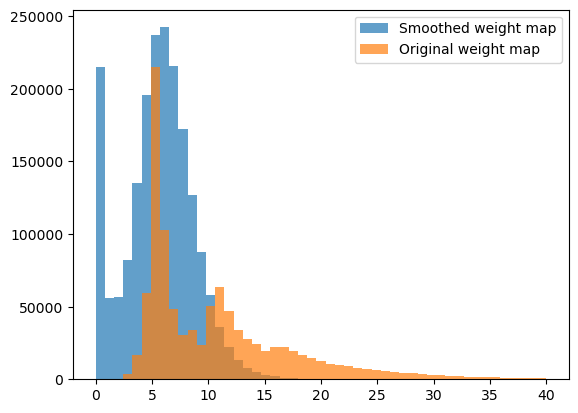

In [64]:
w_plot = smoothed_weight[smoothed_weight > 0]
w0_plot = map_info['weight_mask'][map_info['weight_mask'] > 0]
bins = np.linspace(0, 40, 50)
plt.hist(w_plot, bins=bins, alpha=0.7, label='Smoothed weight map')
plt.hist(w0_plot, bins=bins, alpha=0.7, label='Original weight map')
plt.legend()
plt.show()

In [39]:
crit = np.quantile(w_plot, 1 - len(w0_plot) / len(w_plot))      # the smoothed mask still gives the same number of pixels as the original mask.
smoothed_mask = smoothed_weight > crit

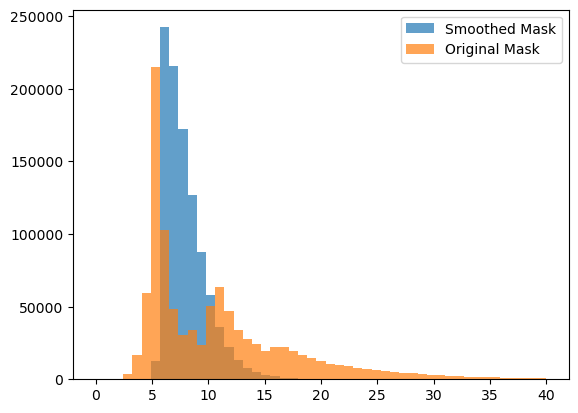

In [40]:
w_plot = smoothed_weight[smoothed_weight > 0]
w0_plot = map_info['weight_mask'][map_info['weight_mask'] > 0]
bins = np.linspace(0, 40, 50)
plt.hist(w_plot[w_plot > crit], bins=bins, alpha=0.7, label='Smoothed Mask')
plt.hist(w0_plot, bins=bins, alpha=0.7, label='Original Mask')
plt.legend()
plt.show()

In [41]:
# 3 a super loose mask (some casual value)
mask_loose = smoothed_weight > 1

([], [])

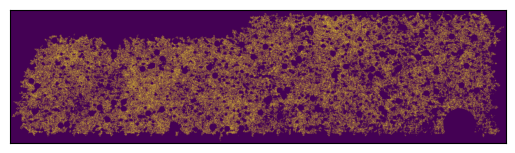

In [51]:
plt.imshow(mask_ratio_0_8, origin='lower')
plt.xticks([])
plt.yticks([])

In [ ]:
# 5 a mask that smoothed_weight / original_weight > 0.8

weight_ratio = smoothed_weight / map_info['weight_mask']
weight_ratio[map_info['weight_mask'] == 0] = 0   # avoid division by zero

mask_ratio_0_8 = weight_ratio > 0.8

/var/tmp/pbs.574163.idark/ipykernel_149715/3398240870.py:3: RuntimeWarning: divide by zero encountered in divide
  weight_ratio = smoothed_weight / map_info['weight_mask']
/var/tmp/pbs.574163.idark/ipykernel_149715/3398240870.py:3: RuntimeWarning: invalid value encountered in divide
  weight_ratio = smoothed_weight / map_info['weight_mask']


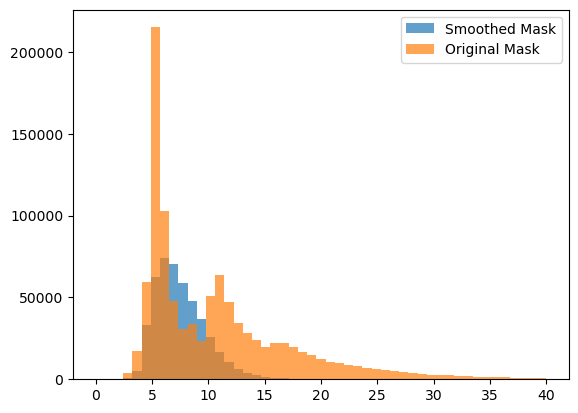

In [43]:
w_plot = smoothed_weight[mask_ratio_0_8]
w0_plot = map_info['weight_mask'][map_info['weight_mask'] > 0]
bins = np.linspace(0, 40, 50)
plt.hist(w_plot, bins=bins, alpha=0.7, label='Smoothed Mask')
plt.hist(w0_plot, bins=bins, alpha=0.7, label='Original Mask')
plt.legend()
plt.show()

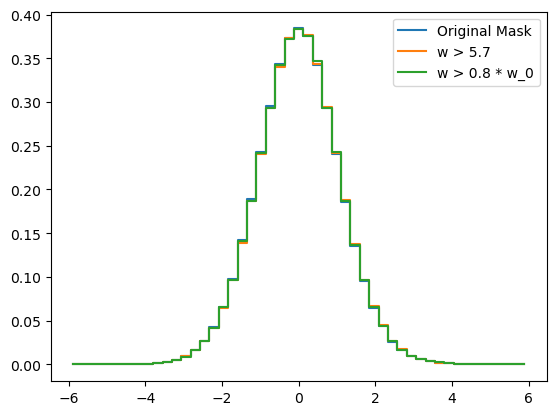

In [53]:
x, y, err = compute_pdf(~original_mask)
plt.plot(x, y, drawstyle='steps-mid', label='Original Mask')
x, y, err = compute_pdf(~smoothed_mask)
plt.plot(x, y, drawstyle='steps-mid', label='w > {:.2g}'.format(crit))
# x, y, err = compute_pdf(~mask_loose)
# plt.plot(x, y, drawstyle='steps-mid', label='Loose Mask')
# x, y, err = compute_pdf(~mask_tight)
# plt.plot(x, y, drawstyle='steps-mid', label='Tight Mask')
x, y, err = compute_pdf(~mask_ratio_0_8)
plt.plot(x, y, drawstyle='steps-mid', label='w > 0.8 * w_0')

plt.legend()
plt.show()

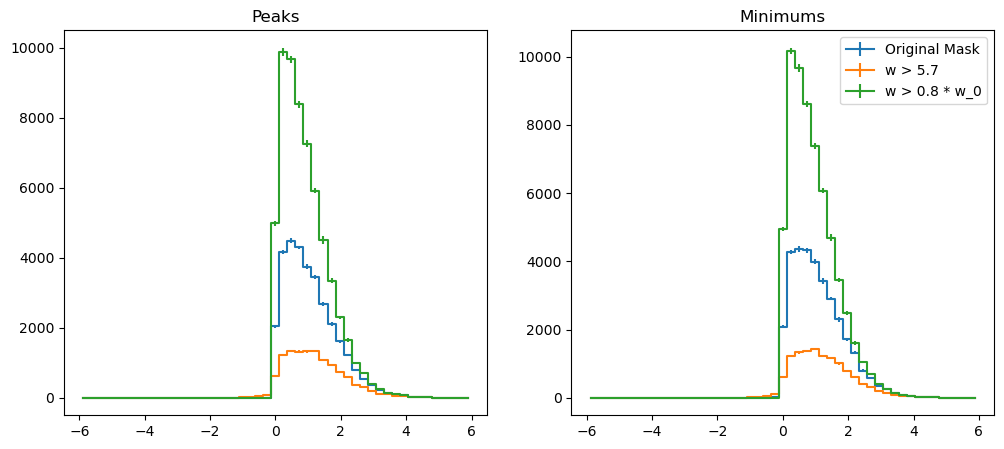

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

x, p, m, perr, merr = compute_p_m(~original_mask)
axes[0].errorbar(x, p, yerr=perr, drawstyle='steps-mid', label='Original Mask')
axes[1].errorbar(x, m, yerr=merr, drawstyle='steps-mid', label='Original Mask')
x, p, m, perr, merr = compute_p_m(~smoothed_mask)
axes[0].errorbar(x, p, yerr=perr, drawstyle='steps-mid', label='w > {:.2g}'.format(crit))
axes[1].errorbar(x, m, yerr=merr, drawstyle='steps-mid', label='w > {:.2g}'.format(crit))
# x, p, m, perr, merr = compute_p_m(~mask_loose)
# axes[0].errorbar(x, p, yerr=perr, drawstyle='steps-mid', label='Loose Mask')
# axes[1].errorbar(x, m, yerr=merr, drawstyle='steps-mid', label='Loose Mask')
# x, p, m, perr, merr = compute_p_m(~mask_tight)
# axes[0].errorbar(x, p, yerr=perr, drawstyle='steps-mid', label='Tight Mask')
# axes[1].errorbar(x, m, yerr=merr, drawstyle='steps-mid', label='Tight Mask')
x, p, m, perr, merr = compute_p_m(~mask_ratio_0_8)
axes[0].errorbar(x, p, yerr=perr, drawstyle='steps-mid', label='w > 0.8 * w_0')
axes[1].errorbar(x, m, yerr=merr, drawstyle='steps-mid', label='w > 0.8 * w_0')


axes[0].set_title('Peaks')
axes[1].set_title('Minimums')

plt.legend()
plt.show()

/misc/home/hedi/HSCNG/hsc_y3_utils/stats_code.py:85: RuntimeWarning: invalid value encountered in divide
  frac = (2*kx*ky*kxy - kx**2*kyy -ky**2*kxx)/(kx**2+ky**2)


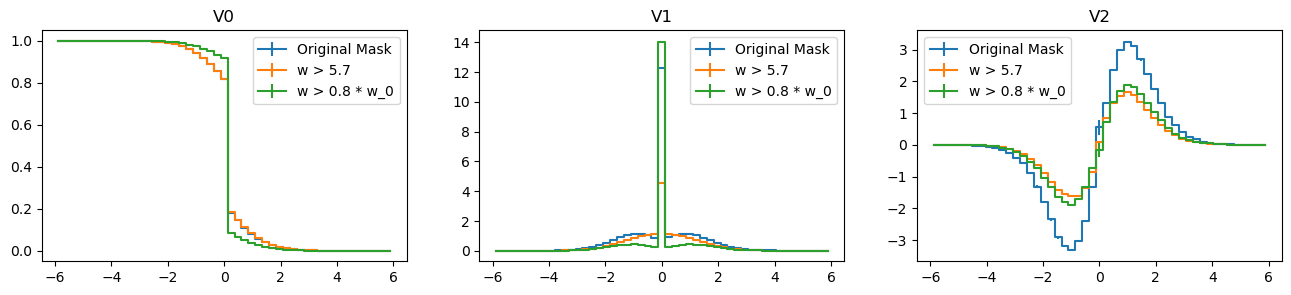

In [58]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3))


masks = [
    ~original_mask,
    ~smoothed_mask,
    # ~mask_loose,
    # ~mask_tight,
    ~mask_ratio_0_8
]
labels = [
    'Original Mask',
    'w > {:.2g}'.format(crit),
    # 'Loose Mask',
    # 'Tight Mask',
    'w > 0.8 * w_0'
]

for mask, label in zip(masks, labels):
    x, V0, V1, V2, V0err, V1err, V2err = compute_MF(mask)
    axes[0].errorbar(x, V0, yerr=V0err, drawstyle='steps-mid', label=label)
    axes[1].errorbar(x, V1*1e2, yerr=V1err*1e2, drawstyle='steps-mid', label=label)
    axes[2].errorbar(x, V2*1e3, yerr=V2err*1e3, drawstyle='steps-mid', label=label)

axes[0].set_title('V0')
axes[1].set_title('V1')
axes[2].set_title('V2')
axes[0].legend()
axes[1].legend()
axes[2].legend()

plt.show()

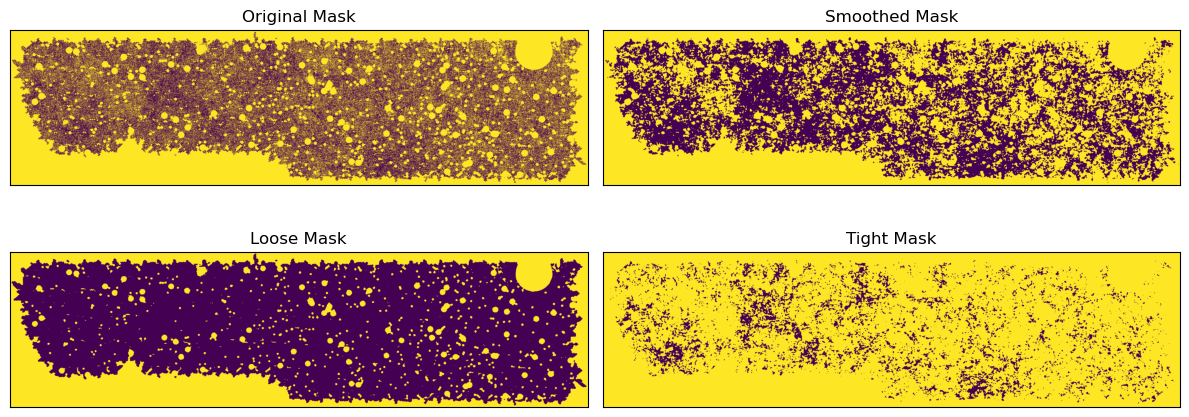

In [64]:
fig, axes = plt.subplots(2, 2, figsize=(12, 5))

masks = [
    ~original_mask,
    ~smoothed_mask,
    ~mask_loose,
    ~mask_tight
]
labels = [
    'Original Mask',
    'Smoothed Mask',
    'Loose Mask',
    'Tight Mask'
]

axes = axes.flatten()
for mask, label, ax in zip(masks, labels, axes):
    ax.imshow(mask)
    ax.set_title(label)
    ax.set_xticks([])
    ax.set_yticks([])

fig.tight_layout()
fig.show()